In [1]:
# Import required libraries

import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Dataset configuration

DATASET_PATH = "/kaggle/input/datasets/i212385nomanarif/2024-brats-glioma"

PATIENT_ID = "BraTS-GLI-02547-101"

PATIENT_PATH = os.path.join(DATASET_PATH, PATIENT_ID)

# File paths

T1C_PATH = os.path.join(PATIENT_PATH, f"{PATIENT_ID}-t1c.nii")
FLAIR_PATH = os.path.join(PATIENT_PATH, f"{PATIENT_ID}-t2f.nii")
SEG_PATH = os.path.join(PATIENT_PATH, f"{PATIENT_ID}-seg.nii")

print("Patient:", PATIENT_ID)
print("Patient directory exists:", os.path.exists(PATIENT_PATH))

Patient: BraTS-GLI-02547-101
Patient directory exists: True


In [2]:
# Load NIfTI files

t1c_img = nib.load(T1C_PATH)
flair_img = nib.load(FLAIR_PATH)
seg_img = nib.load(SEG_PATH)

# Convert all volumes to canonical RAS+ orientation

t1c_img = nib.as_closest_canonical(t1c_img)
flair_img = nib.as_closest_canonical(flair_img)
seg_img = nib.as_closest_canonical(seg_img)

# Extract voxel arrays

t1c = t1c_img.get_fdata()
flair = flair_img.get_fdata()

# Segmentation labels are categorical, so preserve integer values
seg = seg_img.get_fdata().astype(np.int16)

print("T1c shape:", t1c.shape)
print("FLAIR shape:", flair.shape)
print("Segmentation shape:", seg.shape)

T1c shape: (182, 218, 182)
FLAIR shape: (182, 218, 182)
Segmentation shape: (182, 218, 182)


In [3]:
# Identify unique segmentation labels

unique_labels, label_counts = np.unique(
    seg,
    return_counts=True
)

total_voxels = seg.size

print("Unique segmentation labels:\n")

for label, count in zip(unique_labels, label_counts):

    percentage = (count / total_voxels) * 100

    print(
        f"Label {label}: "
        f"{count:,} voxels "
        f"({percentage:.4f}%)"
    )

Unique segmentation labels:

Label 0: 7,205,203 voxels (99.7808%)
Label 1: 49 voxels (0.0007%)
Label 2: 12,902 voxels (0.1787%)
Label 3: 2,509 voxels (0.0347%)
Label 4: 369 voxels (0.0051%)


In [4]:
# Check whether all volumes have identical shapes

print("Shape consistency:")
print("T1c vs FLAIR:", t1c.shape == flair.shape)
print("T1c vs Segmentation:", t1c.shape == seg.shape)

# Check affine matrices

print("\nAffine consistency:")
print("T1c vs FLAIR:", np.allclose(t1c_img.affine, flair_img.affine))
print("T1c vs Segmentation:", np.allclose(t1c_img.affine, seg_img.affine))

# Display affine matrices

print("\nT1c Affine:\n", t1c_img.affine)
print("\nSegmentation Affine:\n", seg_img.affine)

Shape consistency:
T1c vs FLAIR: True
T1c vs Segmentation: True

Affine consistency:
T1c vs FLAIR: True
T1c vs Segmentation: True

T1c Affine:
 [[   1.    0.    0.  -91.]
 [   0.    1.    0. -126.]
 [   0.    0.    1.  -72.]
 [   0.    0.    0.    1.]]

Segmentation Affine:
 [[   1.    0.    0.  -91.]
 [   0.    1.    0. -126.]
 [   0.    0.    1.  -72.]
 [   0.    0.    0.    1.]]


In [7]:
def visualize_segmentation_3d(
    volume,
    slice_indices=None,
    figsize=(16, 5),
    title="Ground-Truth Segmentation Mask"
):
    """
    Visualize a 3D segmentation volume in axial, coronal
    and sagittal planes.

    If slice_indices is None, automatically selects the
    slice containing the maximum number of non-background voxels.
    """

    if volume.ndim != 3:
        raise ValueError("Expected a 3D volume.")

    # Automatically find slices with maximum foreground voxels
    if slice_indices is None:

        foreground = volume > 0

        x = np.argmax(np.sum(foreground, axis=(1, 2)))
        y = np.argmax(np.sum(foreground, axis=(0, 2)))
        z = np.argmax(np.sum(foreground, axis=(0, 1)))

    else:
        x, y, z = slice_indices

    fig, axes = plt.subplots(1, 3, figsize=figsize)

    # Axial
    axes[0].imshow(
        volume[:, :, z].T,
        cmap="gray",
        origin="lower"
    )
    axes[0].set_title(f"Axial (Z = {z})")

    # Coronal
    axes[1].imshow(
        volume[:, y, :].T,
        cmap="gray",
        origin="lower"
    )
    axes[1].set_title(f"Coronal (Y = {y})")

    # Sagittal
    axes[2].imshow(
        volume[x, :, :].T,
        cmap="gray",
        origin="lower"
    )
    axes[2].set_title(f"Sagittal (X = {x})")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

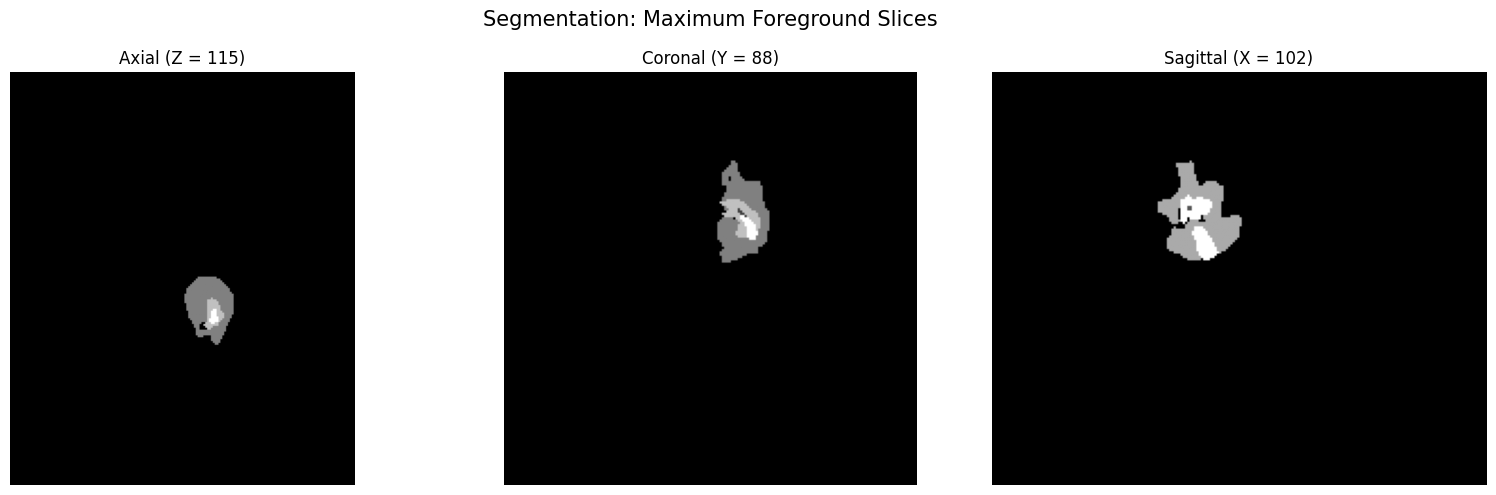

In [8]:
visualize_segmentation_3d(
    seg,
    title="Segmentation: Maximum Foreground Slices"
)

In [9]:
# Define a colour for each segmentation label

SEGMENTATION_COLORS = [
    "black",       # Label 0: Background
    "red",         # Label 1
    "green",       # Label 2
    "blue",        # Label 3
    "yellow"       # Label 4
]

SEGMENTATION_LABELS = [
    "Background",
    "Label 1",
    "Label 2",
    "Label 3",
    "Label 4"
]

# Create discrete colormap and normalization

seg_cmap = ListedColormap(SEGMENTATION_COLORS)

seg_norm = BoundaryNorm(
    boundaries=np.arange(-0.5, 5.5, 1),
    ncolors=seg_cmap.N
)

In [14]:
# Mapping between numerical segmentation labels and their meanings.
SEGMENTATION_LABELS = {
    0: "Background",
    1: "NETC - Non-Enhancing Tumor Core",
    2: "SNFH - Surrounding Non-Enhancing FLAIR Hyperintensity",
    3: "ET - Enhancing Tumor",
    4: "RC - Resection Cavity"
}

# Assign a distinct colour to each segmentation label.
SEGMENTATION_COLORS = [
    "black",   # 0: Background
    "red",     # 1: NETC
    "green",   # 2: SNFH
    "blue",    # 3: ET
    "yellow"   # 4: RC
]

# Create a discrete colormap: each integer label gets one fixed colour.
seg_cmap = ListedColormap(SEGMENTATION_COLORS)

# Ensure that values are mapped to their respective integer labels.
seg_norm = BoundaryNorm(
    boundaries=np.arange(-0.5, 5.5, 1),
    ncolors=seg_cmap.N
)


def visualize_segmentation_labels(volume, slice_indices=None):
    """
    Visualize segmentation labels in axial, coronal and sagittal planes.

    Each label is represented by a distinct colour.
    """

    if volume.ndim != 3:
        raise ValueError("Expected a 3D segmentation volume.")

    # Automatically select slices containing the maximum tumour area.
    if slice_indices is None:
        foreground = volume > 0

        x = np.argmax(np.sum(foreground, axis=(1, 2)))
        y = np.argmax(np.sum(foreground, axis=(0, 2)))
        z = np.argmax(np.sum(foreground, axis=(0, 1)))

    else:
        x, y, z = slice_indices

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # Extract the three anatomical planes.
    slices = [
        volume[:, :, z].T,  # Axial
        volume[:, y, :].T,  # Coronal
        volume[x, :, :].T   # Sagittal
    ]

    plane_names = [
        f"Axial (Z={z})",
        f"Coronal (Y={y})",
        f"Sagittal (X={x})"
    ]

    for ax, image, name in zip(axes, slices, plane_names):

        ax.imshow(
            image,
            cmap=seg_cmap,
            norm=seg_norm,
            origin="lower",
            interpolation="nearest"
        )

        ax.set_title(name, fontsize=12)
        ax.axis("off")

    # Create a legend using the label names and their corresponding colours.
    legend_elements = [
        Patch(
            facecolor=SEGMENTATION_COLORS[label],
            label=SEGMENTATION_LABELS[label]
        )
        for label in range(1, 5)
    ]

    fig.legend(
        handles=legend_elements,
        loc="lower center",
        ncol=2,
        fontsize=10
    )

    plt.suptitle("Colour-Coded Ground-Truth Segmentation", fontsize=15)
    plt.tight_layout(rect=[0, 0.12, 1, 0.95])
    plt.show()

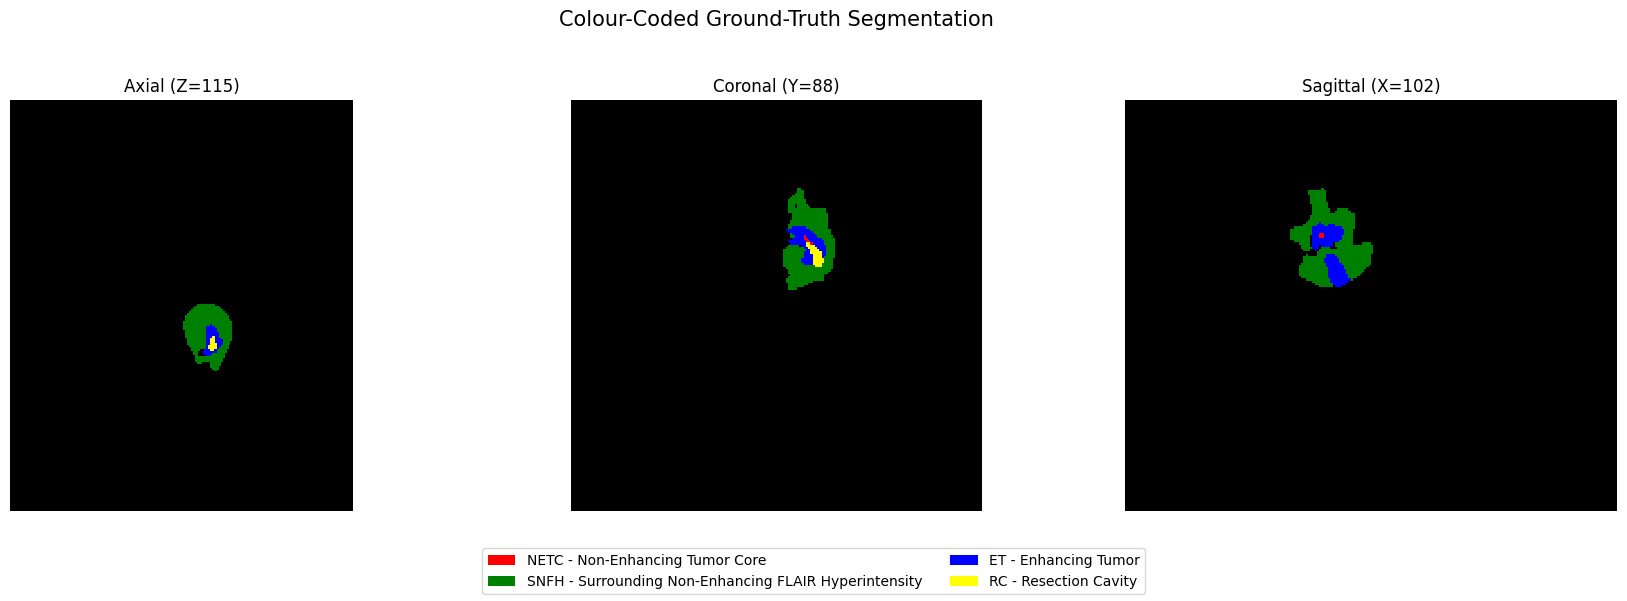

In [16]:
visualize_segmentation_labels(
    seg
)

In [17]:
def visualize_segmentation_overlay(
    mri_volume,
    segmentation,
    slice_indices=None,
    modality_name="T1c"
):
    """
    Overlay ground-truth segmentation labels on an MRI volume
    across axial, coronal and sagittal planes.
    """

    if mri_volume.shape != segmentation.shape:
        raise ValueError("MRI and segmentation volumes must have matching shapes.")

    # Automatically select slices containing the maximum tumour area.
    if slice_indices is None:
        foreground = segmentation > 0

        x = np.argmax(np.sum(foreground, axis=(1, 2)))
        y = np.argmax(np.sum(foreground, axis=(0, 2)))
        z = np.argmax(np.sum(foreground, axis=(0, 1)))

    else:
        x, y, z = slice_indices

    # Extract MRI slices.
    mri_slices = [
        mri_volume[:, :, z].T,
        mri_volume[:, y, :].T,
        mri_volume[x, :, :].T
    ]

    # Extract corresponding segmentation slices.
    seg_slices = [
        segmentation[:, :, z].T,
        segmentation[:, y, :].T,
        segmentation[x, :, :].T
    ]

    plane_names = [
        f"Axial (Z={z})",
        f"Coronal (Y={y})",
        f"Sagittal (X={x})"
    ]

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    for ax, mri_slice, seg_slice, name in zip(
        axes, mri_slices, seg_slices, plane_names
    ):

        # Display the underlying MRI image.
        ax.imshow(
            mri_slice,
            cmap="gray",
            origin="lower"
        )

        # Hide background voxels so only tumour labels appear.
        masked_segmentation = np.ma.masked_where(
            seg_slice == 0,
            seg_slice
        )

        # Overlay the colour-coded segmentation.
        ax.imshow(
            masked_segmentation,
            cmap=seg_cmap,
            norm=seg_norm,
            alpha=0.55,
            origin="lower",
            interpolation="nearest"
        )

        ax.set_title(name, fontsize=12)
        ax.axis("off")

    # Add legend for the tumour regions.
    legend_elements = [
        Patch(
            facecolor=SEGMENTATION_COLORS[label],
            label=SEGMENTATION_LABELS[label]
        )
        for label in range(1, 5)
    ]

    fig.legend(
        handles=legend_elements,
        loc="lower center",
        ncol=2,
        fontsize=10
    )

    plt.suptitle(
        f"{modality_name} MRI with Ground-Truth Segmentation Overlay",
        fontsize=15
    )

    plt.tight_layout(rect=[0, 0.12, 1, 0.95])
    plt.show()

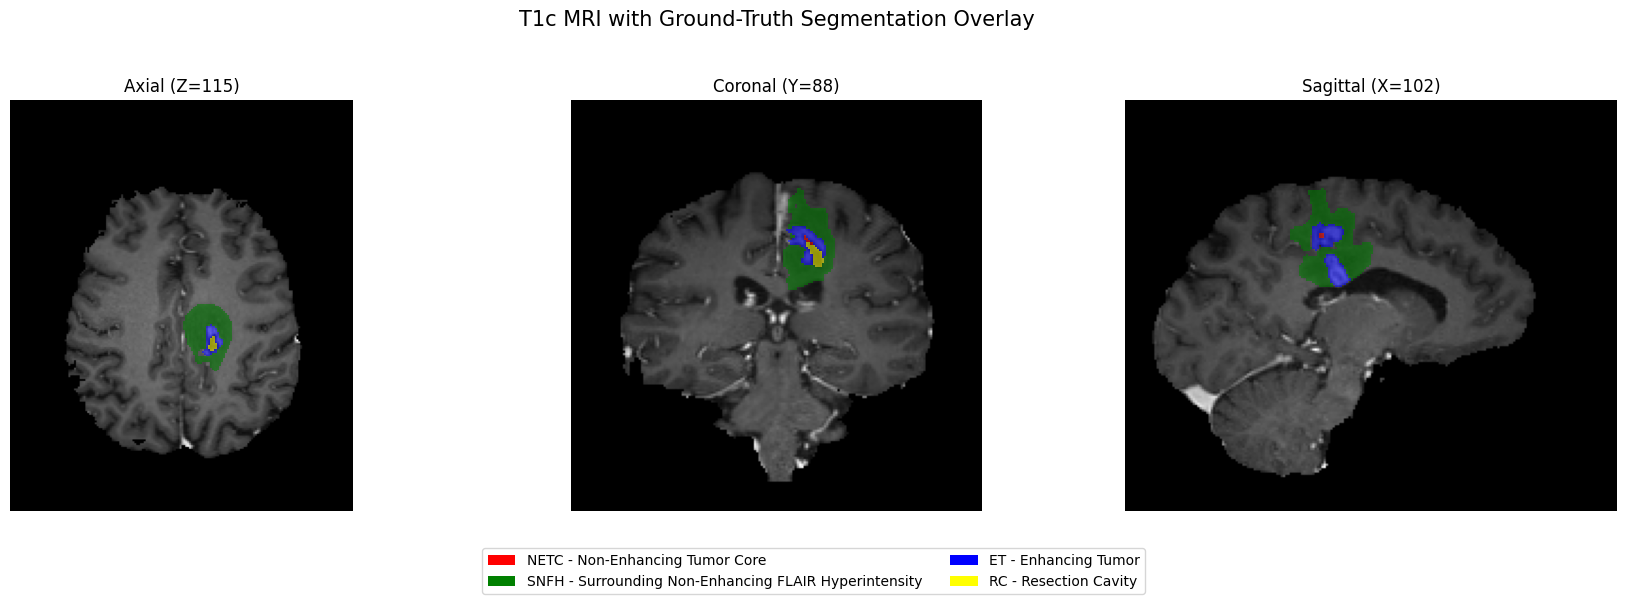

In [18]:
visualize_segmentation_overlay(t1c, seg, modality_name="T1c")

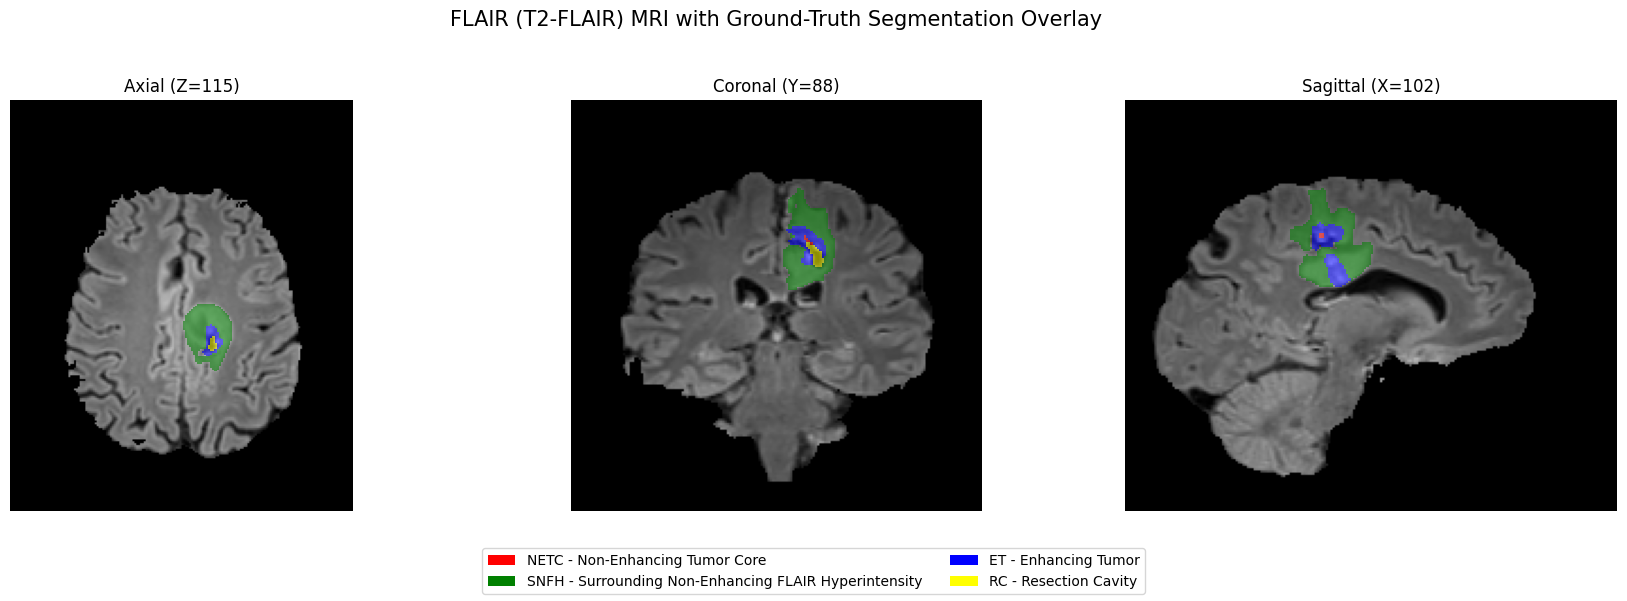

In [19]:
# Visualize ground-truth segmentation over the FLAIR MRI modality.
visualize_segmentation_overlay(
    flair,
    seg,
    modality_name="FLAIR (T2-FLAIR)"
)

In [20]:
# Calculate physical volume of one voxel in mm³.
voxel_spacing = seg_img.header.get_zooms()[:3]
voxel_volume_mm3 = np.prod(voxel_spacing)

# Convert voxel counts into physical volumes.
region_statistics = []

for label, region_name in SEGMENTATION_LABELS.items():

    if label == 0:
        continue

    voxel_count = np.sum(seg == label)

    volume_mm3 = voxel_count * voxel_volume_mm3
    volume_ml = volume_mm3 / 1000

    region_statistics.append({
        "Label": label,
        "Region": region_name,
        "Voxel Count": voxel_count,
        "Volume (mm³)": round(volume_mm3, 2),
        "Volume (mL)": round(volume_ml, 4)
    })

import pandas as pd

region_df = pd.DataFrame(region_statistics)

print("Voxel spacing:", voxel_spacing, "mm")
print("Single voxel volume:", voxel_volume_mm3, "mm³")

display(region_df)

Voxel spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0)) mm
Single voxel volume: 1.0 mm³


,Label,Region,Voxel Count,Volume (mm³),Volume (mL)
0,1,NETC - Non-Enhancing Tumor Core,49,49.0,0.049
1,2,SNFH - Surrounding Non-Enhancing FLAIR Hyperin...,12902,12902.0,12.902
2,3,ET - Enhancing Tumor,2509,2509.0,2.509
3,4,RC - Resection Cavity,369,369.0,0.369


In [21]:
# Construct the composite segmentation regions.
composite_regions = {
    "ET": np.isin(seg, [3]),
    "TC": np.isin(seg, [1, 3]),
    "WT": np.isin(seg, [1, 2, 3]),
    "RC": np.isin(seg, [4])
}

composite_statistics = []

for region_name, mask in composite_regions.items():

    voxel_count = np.sum(mask)
    volume_mm3 = voxel_count * voxel_volume_mm3

    composite_statistics.append({
        "Region": region_name,
        "Voxel Count": voxel_count,
        "Volume (mL)": round(volume_mm3 / 1000, 4)
    })

composite_df = pd.DataFrame(composite_statistics)

display(composite_df)

,Region,Voxel Count,Volume (mL)
0,ET,2509,2.509
1,TC,2558,2.558
2,WT,15460,15.460
3,RC,369,0.369
